#Testing


In [ ]:
print("MediBuddy Capstone Project Started Successfully!")

MediBuddy Capstone Project Started Successfully!


#Importing Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("All libraries imported successfully!")

All libraries imported successfully!


#Load Datasets

In [ ]:

price = pd.read_excel(
    "/content/Medibuddy Insurance Data Price (1) (2).xlsx"
)

personal = pd.read_excel(
    "/content/Medibuddy insurance data personal details (1) (2).xlsx"
)

print("Price Dataset Loaded")
print("Personal Dataset Loaded")


Price Dataset Loaded
Personal Dataset Loaded


#Check Dataset Dimensions

In [ ]:

print("Price Dataset Shape:", price.shape)
print("Personal Dataset Shape:", personal.shape)

print("\nPrice Dataset Columns:")
print(price.columns.tolist())

print("\nPersonal Dataset Columns:")
print(personal.columns.tolist())


Price Dataset Shape: (1338, 5)
Personal Dataset Shape: (1338, 4)

Price Dataset Columns:
['Policy no.', 'age', 'sex', 'bmi', 'charges in INR']

Personal Dataset Columns:
['Policy no.', 'children', 'smoker', 'region']


#Merge the Datasets

In [ ]:
df = pd.merge(
    price,
    personal,
    on="Policy no.",
    how="inner"
)
print("Datasets merged successfully!")


Datasets merged successfully!


In [ ]:

print("Merged Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())


Merged Dataset Shape: (1338, 8)

Column Names:
['Policy no.', 'age', 'sex', 'bmi', 'charges in INR', 'children', 'smoker', 'region']

First 5 Records:


,Policy no.,age,sex,bmi,charges in INR,children,smoker,region
0,PLC156898,19,female,27.900,16884.92400,0,yes,southwest
1,PLC156907,18,male,33.770,1725.55230,1,no,southeast
2,PLC156916,28,male,33.000,4449.46200,3,no,southeast
3,PLC156925,33,male,22.705,21984.47061,0,no,northwest
4,PLC156934,32,male,28.880,3866.85520,0,no,northwest


In [ ]:

print("Total missing values:", df.isnull().sum().sum())

print("Duplicate records:", df.duplicated().sum())

print("Unique policy numbers:", df["Policy no."].nunique())


Total missing values: 0
Duplicate records: 0
Unique policy numbers: 1338


# Data Cleaning and Validation

In [ ]:

print("Missing Values in Each Column:")
print(df.isnull().sum())


Missing Values in Each Column:
Policy no.        0
age               0
sex               0
bmi               0
charges in INR    0
children          0
smoker            0
region            0
dtype: int64


In [ ]:

print(df.dtypes)


Policy no.         object
age                 int64
sex                object
bmi               float64
charges in INR    float64
children            int64
smoker             object
region             object
dtype: object


In [ ]:

print("Gender:", df["sex"].unique())

print("Smoker:", df["smoker"].unique())

print("Region:", df["region"].unique())


Gender: ['female' 'male']
Smoker: ['yes' 'no']
Region: ['southwest' 'southeast' 'northwest' 'northeast']


In [ ]:

print("Age range:")
print(df["age"].min(), "-", df["age"].max())

print("\nBMI range:")
print(df["bmi"].min(), "-", df["bmi"].max())

print("\nInsurance charges range:")
print(df["charges in INR"].min(), "-", df["charges in INR"].max())

print("\nChildren range:")
print(df["children"].min(), "-", df["children"].max())


Age range:
18 - 64

BMI range:
15.96 - 53.13

Insurance charges range:
1121.8739 - 63770.42801

Children range:
0 - 5


In [ ]:

display(df.describe())


,age,bmi,charges in INR,children
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,13270.422265,1.094918
std,14.049960,6.098187,12110.011237,1.205493
min,18.000000,15.960000,1121.873900,0.000000
25%,27.000000,26.296250,4740.287150,0.000000
50%,39.000000,30.400000,9382.033000,1.000000
75%,51.000000,34.693750,16639.912515,2.000000
max,64.000000,53.130000,63770.428010,5.000000


In [ ]:

df.to_csv("MediBuddy_Cleaned_Dataset.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


#Exploratory Data Analysis (EDA)

#Insurance Charges Distribution

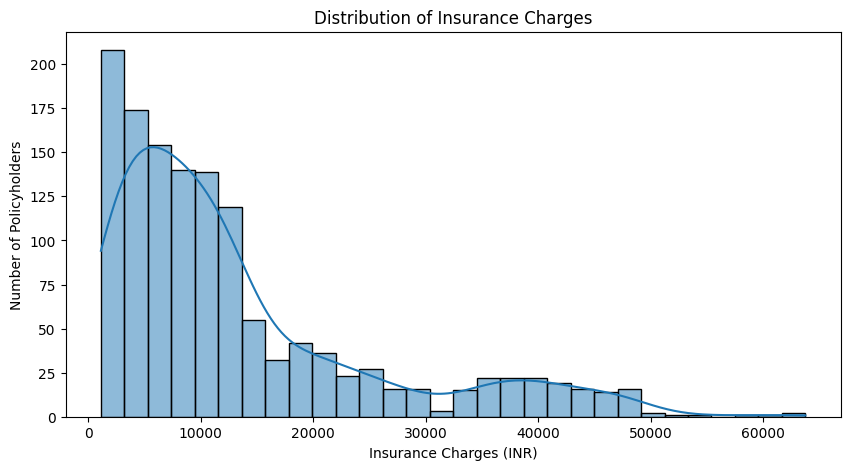

In [ ]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="charges in INR",
    bins=30,
    kde=True
)

plt.title("Distribution of Insurance Charges")
plt.xlabel("Insurance Charges (INR)")
plt.ylabel("Number of Policyholders")

plt.show()


#Age Distribution

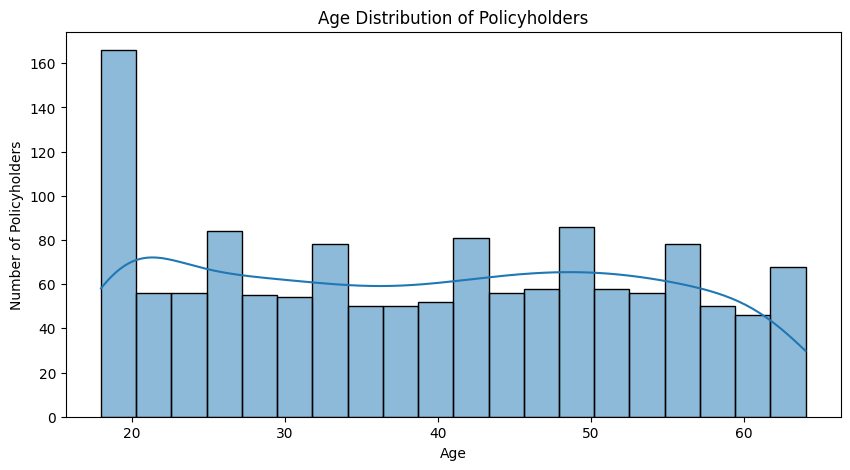

In [ ]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True
)

plt.title("Age Distribution of Policyholders")
plt.xlabel("Age")
plt.ylabel("Number of Policyholders")

plt.show()


#BMI Distribution

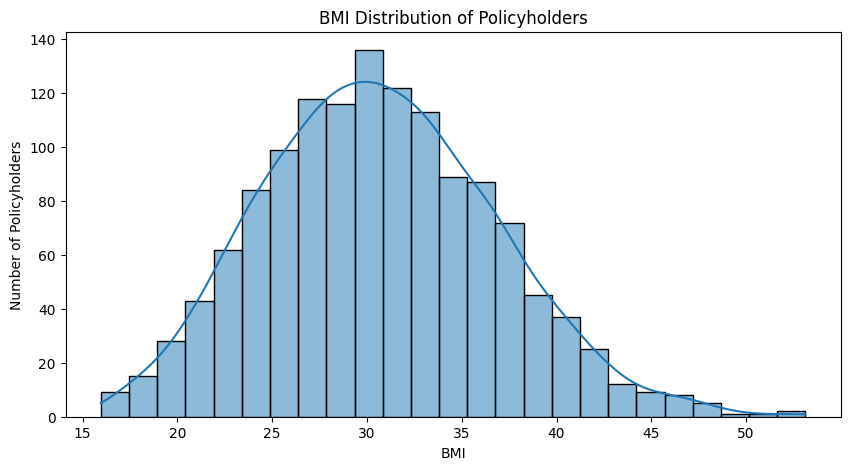

In [ ]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="bmi",
    bins=25,
    kde=True
)

plt.title("BMI Distribution of Policyholders")
plt.xlabel("BMI")
plt.ylabel("Number of Policyholders")

plt.show()


#Analyze Insurance Charges by Gender

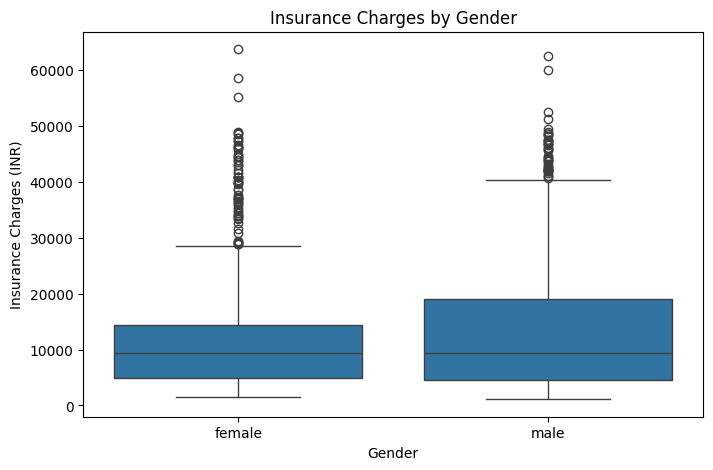

In [ ]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="sex",
    y="charges in INR"
)

plt.title("Insurance Charges by Gender")
plt.xlabel("Gender")
plt.ylabel("Insurance Charges (INR)")

plt.show()


In [ ]:

gender_analysis = df.groupby("sex")["charges in INR"].agg(
    ["mean", "median", "count"]
)

display(gender_analysis)


,mean,median,count
sex,,,
female,12569.578844,9412.96250,662
male,13956.751178,9369.61575,676


In [ ]:

gender_mean = df.groupby("sex")["charges in INR"].mean()

difference = gender_mean["male"] - gender_mean["female"]

print("Difference in average charges:", difference)


Difference in average charges: 1387.1723338865468


#Analyze Insurance Charges by Smoking Status


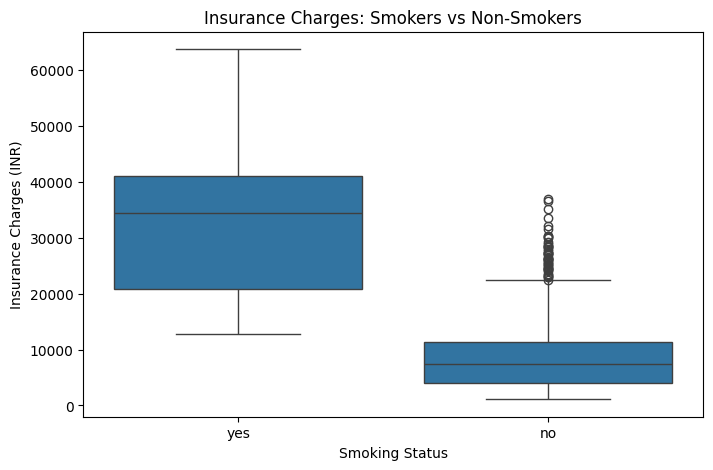

In [ ]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="smoker",
    y="charges in INR"
)

plt.title("Insurance Charges: Smokers vs Non-Smokers")
plt.xlabel("Smoking Status")
plt.ylabel("Insurance Charges (INR)")

plt.show()


In [ ]:

smoker_analysis = df.groupby("smoker")["charges in INR"].agg(
    ["mean", "median", "count"]
)

display(smoker_analysis)


,mean,median,count
smoker,,,
no,8434.268298,7345.40530,1064
yes,32050.231832,34456.34845,274


In [ ]:

smoker_mean = df.groupby("smoker")["charges in INR"].mean()

difference = smoker_mean["yes"] - smoker_mean["no"]

print("Difference in average charges:", difference)

print("Smokers average:", smoker_mean["yes"])

print("Non-smokers average:", smoker_mean["no"])


Difference in average charges: 23615.963533676644
Smokers average: 32050.23183153285
Non-smokers average: 8434.268297856202


#Analyze Insurance Charges by Geographic Region


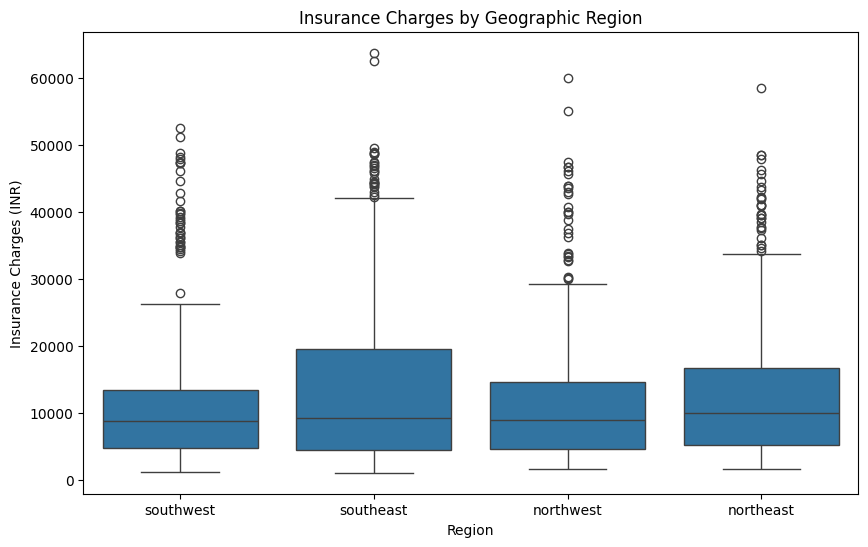

In [ ]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="region",
    y="charges in INR"
)

plt.title("Insurance Charges by Geographic Region")
plt.xlabel("Region")
plt.ylabel("Insurance Charges (INR)")

plt.show()


In [ ]:

region_analysis = df.groupby("region")["charges in INR"].agg(
    ["mean", "median", "count"]
)

display(region_analysis)


,mean,median,count
region,,,
northeast,13406.384516,10057.652025,324
northwest,12417.575374,8965.795750,325
southeast,14735.411438,9294.131950,364
southwest,12346.937377,8798.593000,325


In [ ]:

region_mean = df.groupby("region")["charges in INR"].mean()

print("Highest average charges:")
print(region_mean.idxmax(), region_mean.max())

print("\nLowest average charges:")
print(region_mean.idxmin(), region_mean.min())


Highest average charges:
southeast 14735.41143760989

Lowest average charges:
southwest 12346.937377292308


#Analyze Dependents and Insurance Charges


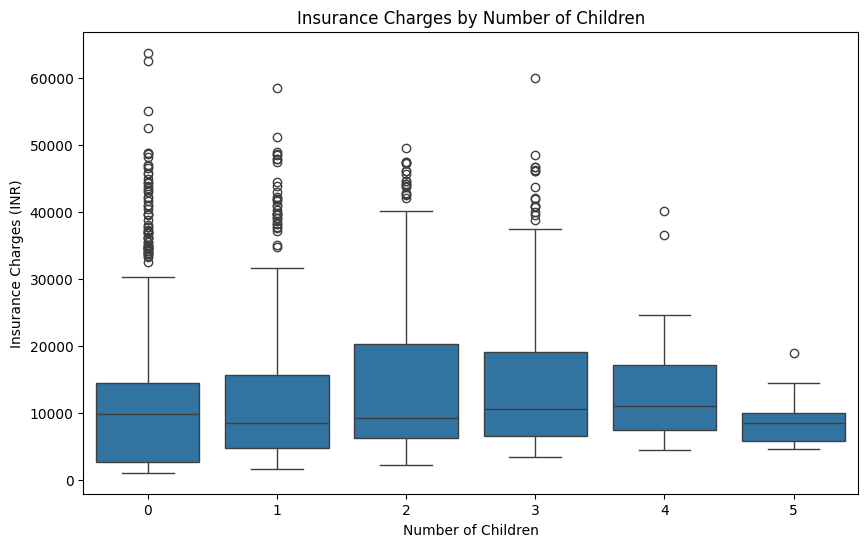

In [ ]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="children",
    y="charges in INR"
)

plt.title("Insurance Charges by Number of Children")
plt.xlabel("Number of Children")
plt.ylabel("Insurance Charges (INR)")

plt.show()


In [ ]:

children_analysis = df.groupby("children")["charges in INR"].agg(
    ["mean", "median", "count"]
)

display(children_analysis)


,mean,median,count
children,,,
0,12365.975602,9856.95190,574
1,12731.171832,8483.87015,324
2,15073.563734,9264.97915,240
3,15355.318367,10600.54830,157
4,13850.656311,11033.66170,25
5,8786.035247,8589.56505,18


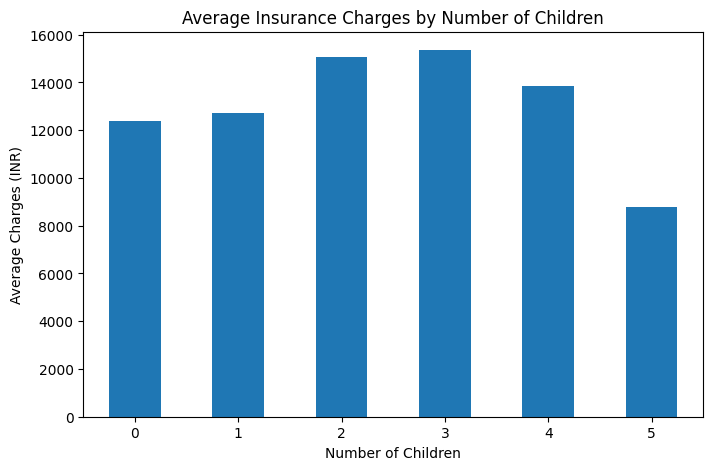

In [ ]:

children_mean = df.groupby("children")["charges in INR"].mean()

plt.figure(figsize=(8, 5))

children_mean.plot(kind="bar")

plt.title("Average Insurance Charges by Number of Children")
plt.xlabel("Number of Children")
plt.ylabel("Average Charges (INR)")

plt.xticks(rotation=0)
plt.show()


#Analyze BMI and Insurance Charges


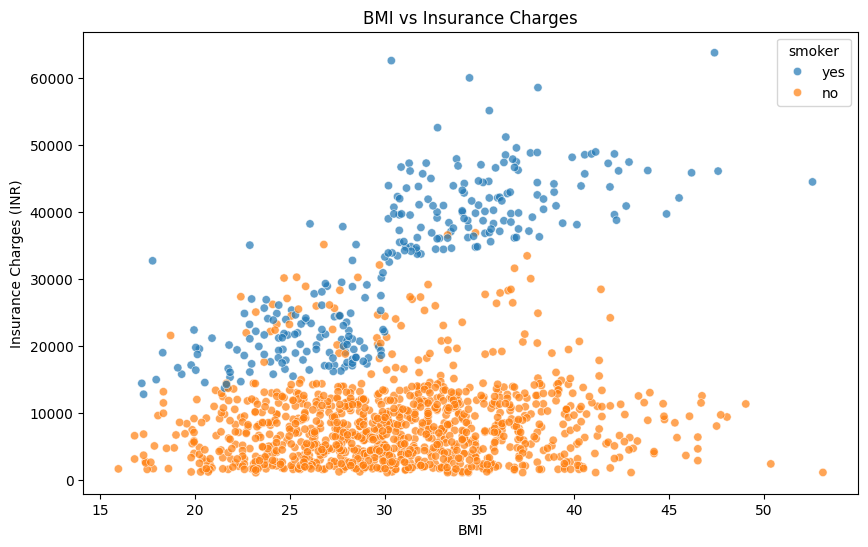

In [ ]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="bmi",
    y="charges in INR",
    hue="smoker",
    alpha=0.7
)

plt.title("BMI vs Insurance Charges")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges (INR)")

plt.show()


In [ ]:

bmi_correlation = df["bmi"].corr(df["charges in INR"])

print("BMI and Insurance Charges Correlation:", bmi_correlation)


BMI and Insurance Charges Correlation: 0.19834096883362895


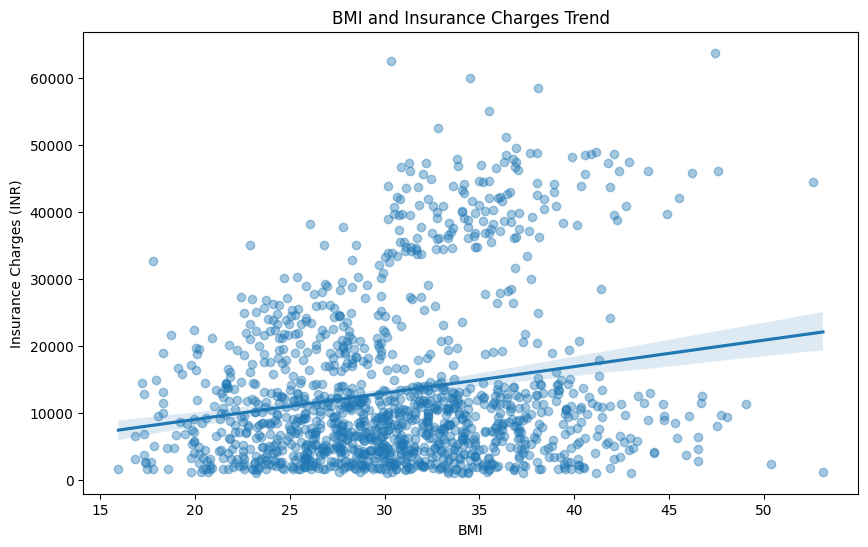

In [ ]:

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="bmi",
    y="charges in INR",
    scatter_kws={"alpha": 0.4}
)

plt.title("BMI and Insurance Charges Trend")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges (INR)")

plt.show()


#Analyze Age and Insurance Charges

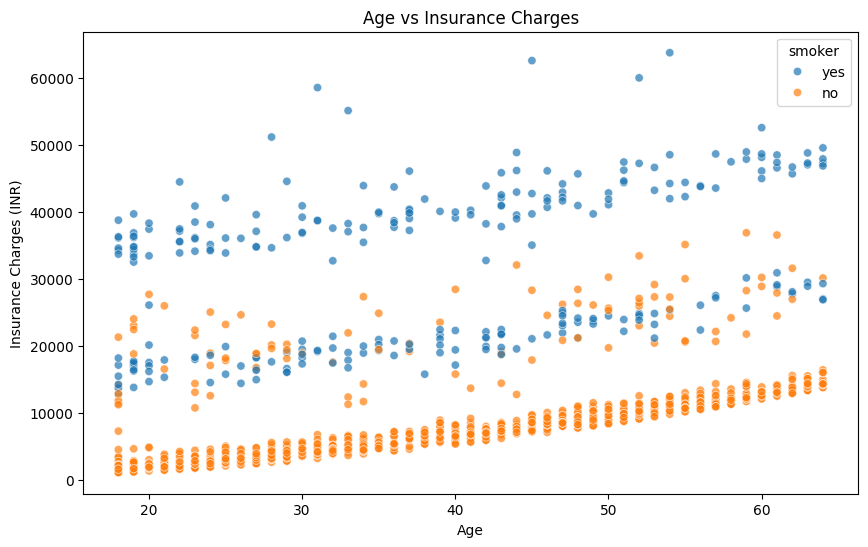

In [ ]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="age",
    y="charges in INR",
    hue="smoker",
    alpha=0.7
)

plt.title("Age vs Insurance Charges")
plt.xlabel("Age")
plt.ylabel("Insurance Charges (INR)")

plt.show()


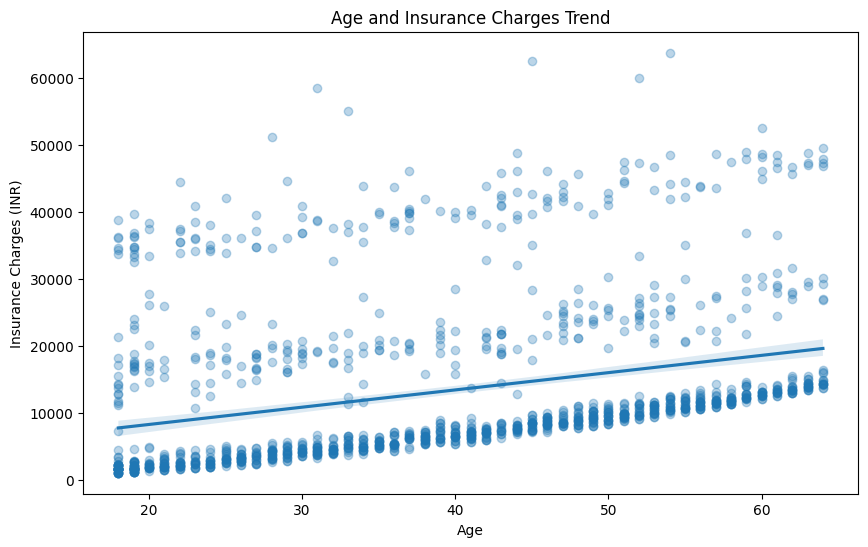

In [ ]:

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="age",
    y="charges in INR",
    scatter_kws={"alpha": 0.3}
)

plt.title("Age and Insurance Charges Trend")
plt.xlabel("Age")
plt.ylabel("Insurance Charges (INR)")

plt.show()


In [ ]:

age_correlation = df["age"].corr(df["charges in INR"])

print("Age and Insurance Charges Correlation:", age_correlation)


Age and Insurance Charges Correlation: 0.29900819333064754


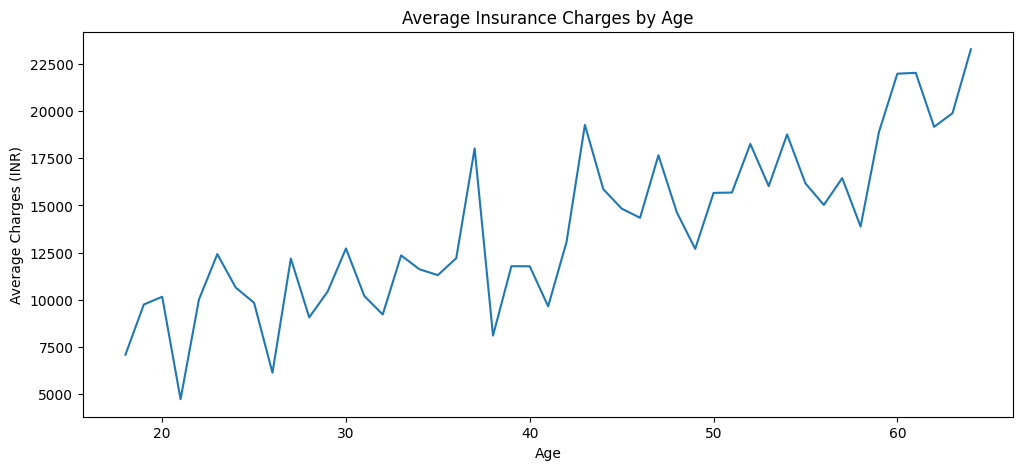

In [ ]:

age_analysis = df.groupby("age")["charges in INR"].mean()

plt.figure(figsize=(12, 5))

age_analysis.plot()

plt.title("Average Insurance Charges by Age")
plt.xlabel("Age")
plt.ylabel("Average Charges (INR)")

plt.show()


#Create a business analysis summary

In [ ]:

print("=" * 60)
print("MEDIBUDDY INSURANCE BUSINESS ANALYSIS")
print("=" * 60)

print("\n1. Overall Average Insurance Charges:")
print(round(df["charges in INR"].mean(), 2))

print("\n2. Average Charges by Gender:")
print(df.groupby("sex")["charges in INR"].mean().round(2))

print("\n3. Average Charges by Smoking Status:")
print(df.groupby("smoker")["charges in INR"].mean().round(2))

print("\n4. Average Charges by Region:")
print(df.groupby("region")["charges in INR"].mean().round(2))

print("\n5. Average Charges by Number of Children:")
print(df.groupby("children")["charges in INR"].mean().round(2))

print("\n6. Age and Charges Correlation:")
print(round(df["age"].corr(df["charges in INR"]), 3))

print("\n7. BMI and Charges Correlation:")
print(round(df["bmi"].corr(df["charges in INR"]), 3))

print("\n8. Overall Median Insurance Charges:")
print(round(df["charges in INR"].median(), 2))


MEDIBUDDY INSURANCE BUSINESS ANALYSIS

1. Overall Average Insurance Charges:
13270.42

2. Average Charges by Gender:
sex
female    12569.58
male      13956.75
Name: charges in INR, dtype: float64

3. Average Charges by Smoking Status:
smoker
no      8434.27
yes    32050.23
Name: charges in INR, dtype: float64

4. Average Charges by Region:
region
northeast    13406.38
northwest    12417.58
southeast    14735.41
southwest    12346.94
Name: charges in INR, dtype: float64

5. Average Charges by Number of Children:
children
0    12365.98
1    12731.17
2    15073.56
3    15355.32
4    13850.66
5     8786.04
Name: charges in INR, dtype: float64

6. Age and Charges Correlation:
0.299

7. BMI and Charges Correlation:
0.198

8. Overall Median Insurance Charges:
9382.03


#Save the business analysis results

In [ ]:

business_summary = df.groupby("sex")["charges in INR"].mean().reset_index()
business_summary.to_csv("Gender_Analysis.csv", index=False)

print("Business analysis summary calculated successfully!")


Business analysis summary calculated successfully!


#Does gender matter as a constraint for extending policies?

In [ ]:

gender_analysis = df.groupby("sex")["charges in INR"].agg(
    ["mean", "median", "count"]
)

display(gender_analysis)


,mean,median,count
sex,,,
female,12569.578844,9412.96250,662
male,13956.751178,9369.61575,676


In [ ]:

male = df[df["sex"] == "male"]["charges in INR"].mean()
female = df[df["sex"] == "female"]["charges in INR"].mean()

percentage_difference = abs(male - female) / female * 100

print("Male Average Charges:", round(male, 2))
print("Female Average Charges:", round(female, 2))
print("Percentage Difference:", round(percentage_difference, 2), "%")


Male Average Charges: 13956.75
Female Average Charges: 12569.58
Percentage Difference: 11.04 %


#What is the average amount of money spent over each policy cover?

In [ ]:

average_charges = df["charges in INR"].mean()

print("Average Insurance Charges per Policy:")
print("₹", round(average_charges, 2))


Average Insurance Charges per Policy:
₹ 13270.42


In [ ]:

total_charges = df["charges in INR"].sum()

print("Total Insurance Charges:")
print("₹", round(total_charges, 2))


Total Insurance Charges:
₹ 17755824.99


In [ ]:

print("Median Charges:", round(df["charges in INR"].median(), 2))

print("Maximum Charges:", round(df["charges in INR"].max(), 2))

print("Minimum Charges:", round(df["charges in INR"].min(), 2))


Median Charges: 9382.03
Maximum Charges: 63770.43
Minimum Charges: 1121.87


#Should MediBuddy offer separate policies based on geographical location?

In [ ]:

region_analysis = df.groupby("region")["charges in INR"].agg(
    ["mean", "median", "count"]
).round(2)

display(region_analysis)


,mean,median,count
region,,,
northeast,13406.38,10057.65,324
northwest,12417.58,8965.80,325
southeast,14735.41,9294.13,364
southwest,12346.94,8798.59,325


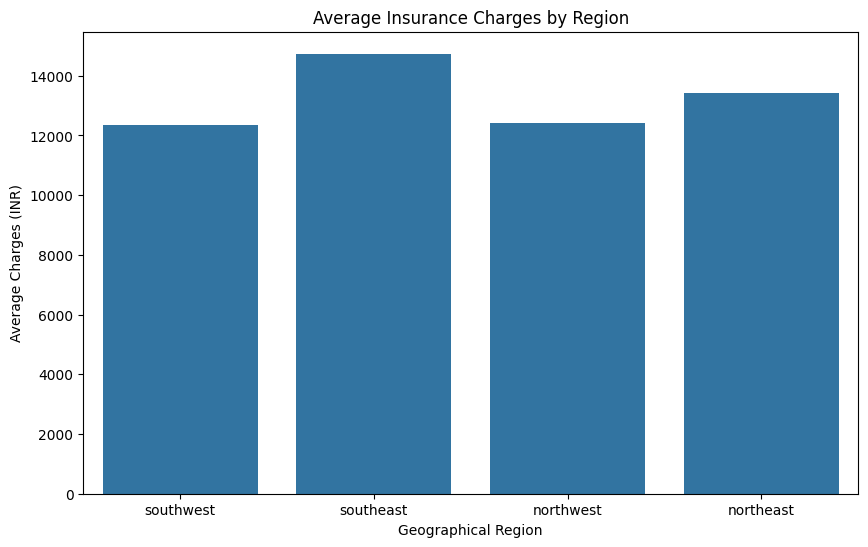

In [ ]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="region",
    y="charges in INR",
    estimator="mean",
    errorbar=None
)

plt.title("Average Insurance Charges by Region")
plt.xlabel("Geographical Region")
plt.ylabel("Average Charges (INR)")

plt.show()


In [ ]:

region_mean = df.groupby("region")["charges in INR"].mean()

print("Highest charging region:")
print(region_mean.idxmax(), round(region_mean.max(), 2))

print("\nLowest charging region:")
print(region_mean.idxmin(), round(region_mean.min(), 2))

print("\nDifference between regions:")
print(round(region_mean.max() - region_mean.min(), 2))


Highest charging region:
southeast 14735.41

Lowest charging region:
southwest 12346.94

Difference between regions:
2388.47


#Does the number of dependents make a difference in insurance charges?

In [ ]:

children_analysis = df.groupby("children")["charges in INR"].agg(
    ["mean", "median", "count"]
).round(2)

display(children_analysis)


,mean,median,count
children,,,
0,12365.98,9856.95,574
1,12731.17,8483.87,324
2,15073.56,9264.98,240
3,15355.32,10600.55,157
4,13850.66,11033.66,25
5,8786.04,8589.57,18


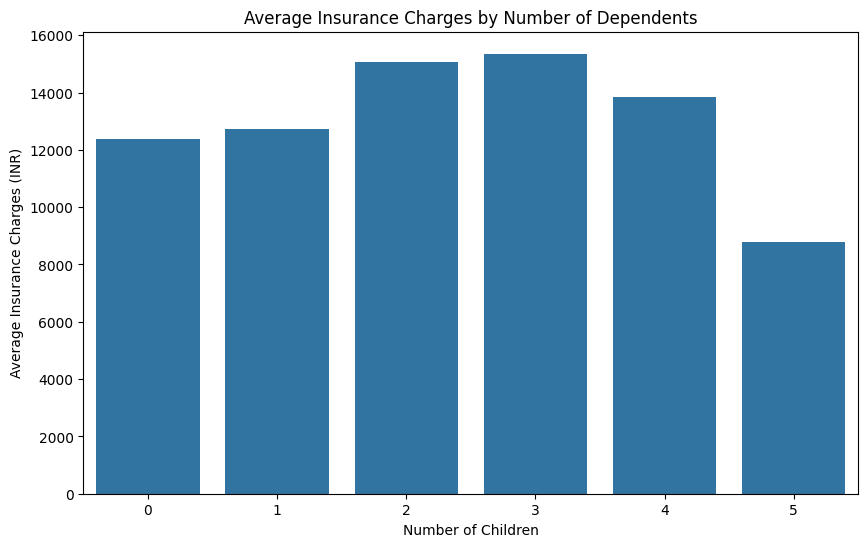

In [ ]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="children",
    y="charges in INR",
    estimator="mean",
    errorbar=None
)

plt.title("Average Insurance Charges by Number of Dependents")
plt.xlabel("Number of Children")
plt.ylabel("Average Insurance Charges (INR)")

plt.show()


In [ ]:

children_corr = df["children"].corr(df["charges in INR"])

print("Correlation between Children and Charges:", round(children_corr, 3))


Correlation between Children and Charges: 0.068


#Does BMI provide useful information about insurance charges?

In [ ]:

bmi_corr = df["bmi"].corr(df["charges in INR"])

print("BMI and Insurance Charges Correlation:")
print(round(bmi_corr, 3))


BMI and Insurance Charges Correlation:
0.198


In [ ]:

df["BMI_Category"] = pd.cut(
    df["bmi"],
    bins=[0, 18.5, 25, 30, 100],
    labels=[
        "Underweight",
        "Normal",
        "Overweight",
        "Obese"
    ],
    right=False
)

bmi_analysis = df.groupby(
    "BMI_Category",
    observed=False
)["charges in INR"].agg(
    ["mean", "median", "count"]
).round(2)

display(bmi_analysis)


,mean,median,count
BMI_Category,,,
Underweight,8852.20,6759.26,20
Normal,10409.34,8603.82,225
Overweight,10987.51,8659.38,386
Obese,15552.34,9964.06,707


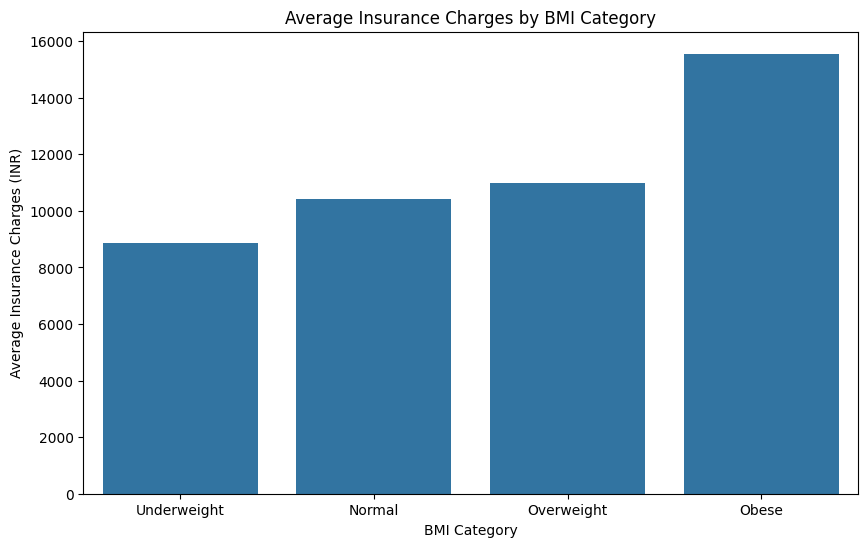

In [ ]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="BMI_Category",
    y="charges in INR",
    estimator="mean",
    errorbar=None
)

plt.title("Average Insurance Charges by BMI Category")
plt.xlabel("BMI Category")
plt.ylabel("Average Insurance Charges (INR)")

plt.show()


#Is it necessary for MediBuddy to understand whether a policyholder is a smoker or non-smoker?

In [ ]:

smoking_analysis = df.groupby("smoker")["charges in INR"].agg(
    ["mean", "median", "count"]
).round(2)

display(smoking_analysis)


,mean,median,count
smoker,,,
no,8434.27,7345.41,1064
yes,32050.23,34456.35,274


In [ ]:

smoker_avg = df[df["smoker"] == "yes"]["charges in INR"].mean()

non_smoker_avg = df[df["smoker"] == "no"]["charges in INR"].mean()

difference = smoker_avg - non_smoker_avg

percentage = (difference / non_smoker_avg) * 100

print("Smoker Average Charges:", round(smoker_avg, 2))
print("Non-Smoker Average Charges:", round(non_smoker_avg, 2))

print("Difference:", round(difference, 2))
print("Percentage Difference:", round(percentage, 2), "%")


Smoker Average Charges: 32050.23
Non-Smoker Average Charges: 8434.27
Difference: 23615.96
Percentage Difference: 280.0 %


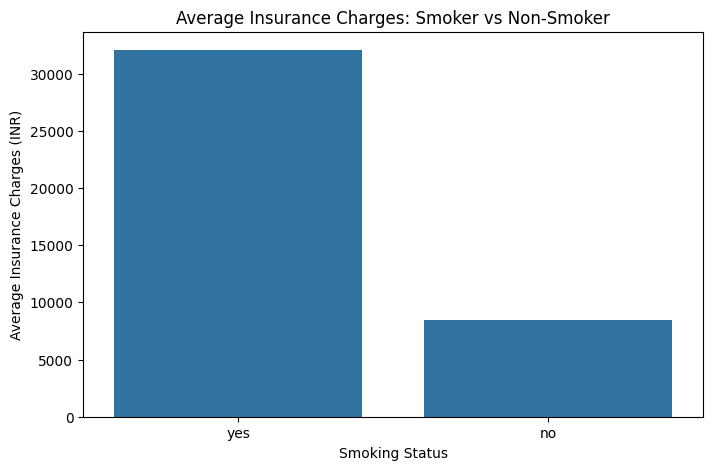

In [ ]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="smoker",
    y="charges in INR",
    estimator="mean",
    errorbar=None
)

plt.title("Average Insurance Charges: Smoker vs Non-Smoker")
plt.xlabel("Smoking Status")
plt.ylabel("Average Insurance Charges (INR)")

plt.show()


#Does age have any influence on insurance charges?

In [ ]:

age_analysis = df.groupby("age")["charges in INR"].agg(
    ["mean", "median", "count"]
).round(2)

display(age_analysis)


,mean,median,count
age,,,
18,7086.22,2198.19,69
19,9747.91,2135.89,68
20,10159.70,2459.72,29
21,4730.46,2254.42,28
22,10012.93,2641.16,28
23,12419.82,3594.54,28
24,10648.02,3045.14,28
25,9838.37,3750.15,28
26,6133.83,3388.88,28


In [ ]:

age_corr = df["age"].corr(df["charges in INR"])

print("Age and Insurance Charges Correlation:")
print(round(age_corr, 3))


Age and Insurance Charges Correlation:
0.299


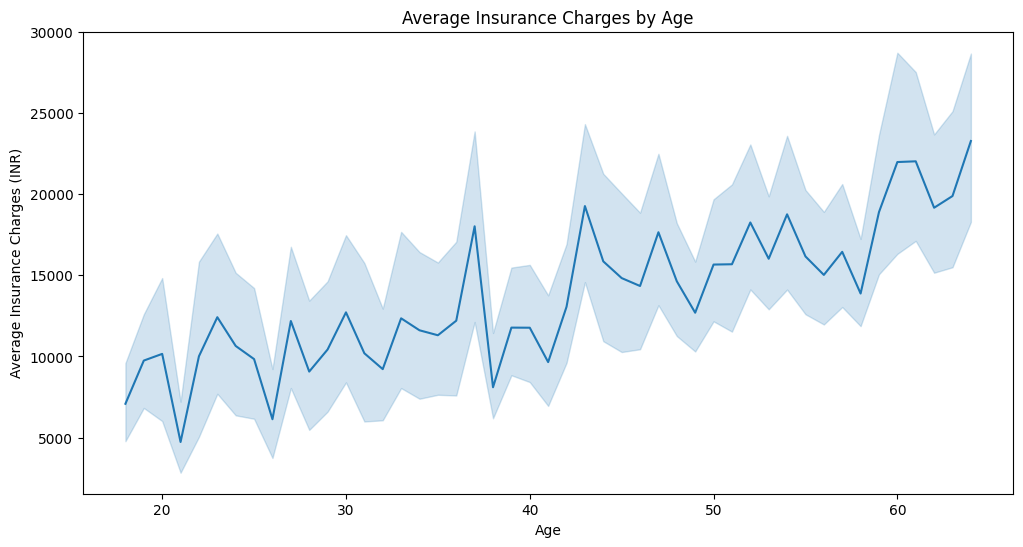

In [ ]:

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df,
    x="age",
    y="charges in INR",
    estimator="mean"
)

plt.title("Average Insurance Charges by Age")
plt.xlabel("Age")
plt.ylabel("Average Insurance Charges (INR)")

plt.show()


#Can MediBuddy offer discounts after checking the health status (BMI)?

In [ ]:

bmi_discount_analysis = df.groupby(
    "BMI_Category",
    observed=False
)["charges in INR"].agg(
    ["mean", "median", "count"]
).round(2)

display(bmi_discount_analysis)


,mean,median,count
BMI_Category,,,
Underweight,8852.20,6759.26,20
Normal,10409.34,8603.82,225
Overweight,10987.51,8659.38,386
Obese,15552.34,9964.06,707


In [ ]:

bmi_smoker_analysis = df.groupby(
    ["BMI_Category", "smoker"],
    observed=False
)["charges in INR"].mean().unstack().round(2)

display(bmi_smoker_analysis)


smoker,no,yes
BMI_Category,,
Underweight,5532.99,18809.82
Normal,7685.66,19942.22
Overweight,8257.96,22495.87
Obese,8842.69,41557.99


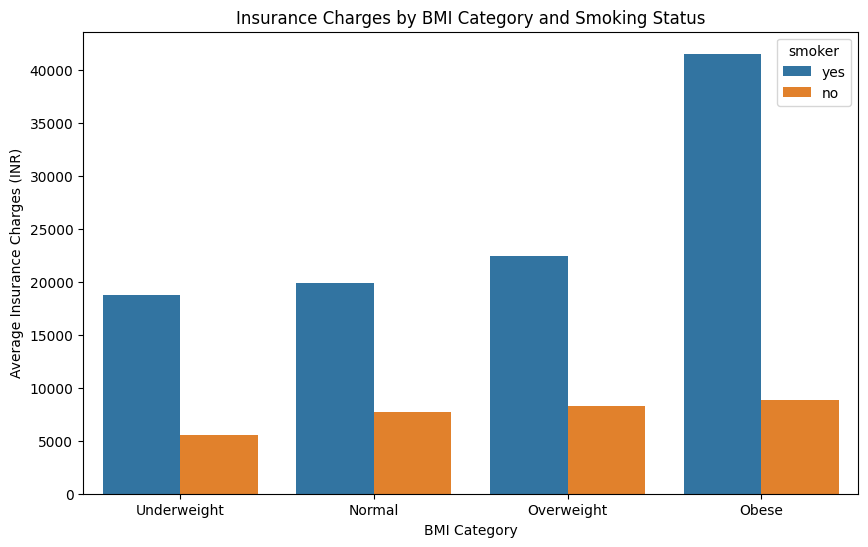

In [ ]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="BMI_Category",
    y="charges in INR",
    hue="smoker",
    estimator="mean",
    errorbar=None
)

plt.title("Insurance Charges by BMI Category and Smoking Status")
plt.xlabel("BMI Category")
plt.ylabel("Average Insurance Charges (INR)")

plt.show()


#Machine Learning — Predict Insurance Charges

In [ ]:

X = df[
    ["age", "sex", "bmi", "children", "smoker", "region"]
]

y = df["charges in INR"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())


Features shape: (1338, 6)
Target shape: (1338,)


,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


In [ ]:

from sklearn.model_selection import train_test_split


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Training records: 1070
Testing records: 268


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression


In [ ]:

categorical_features = ["sex", "smoker", "region"]
numerical_features = ["age", "bmi", "children"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


#Model Evaluation

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression Results")
print("-----------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))


Linear Regression Results
-----------------------
MAE: 4181.19
RMSE: 5796.28
R2 Score: 0.7836


#Train and Compare Multiple ML Models

In [ ]:

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2 Score": round(r2, 4)
    })

model_results = pd.DataFrame(results).sort_values("RMSE")

display(model_results)


,Model,MAE,RMSE,R2 Score
2,Gradient Boosting,2404.90,4328.15,0.8793
1,Random Forest,2541.61,4582.97,0.8647
0,Linear Regression,4181.19,5796.28,0.7836


#Hyperparameter Tuning (Gradient Boosting)

In [ ]:

from sklearn.model_selection import GridSearchCV

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(random_state=42))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3]
}

grid_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(round(np.sqrt(-grid_search.best_score_), 2))


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}

Best Cross-Validation RMSE:
4619.76


#Evaluate the Tuned Model

In [ ]:

best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)

mae_tuned = mean_absolute_error(y_test, y_pred_tuned)
rmse_tuned = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
r2_tuned = r2_score(y_test, y_pred_tuned)

print("Tuned Gradient Boosting Results")
print("--------------------------------")
print("MAE:", round(mae_tuned, 2))
print("RMSE:", round(rmse_tuned, 2))
print("R2 Score:", round(r2_tuned, 4))


Tuned Gradient Boosting Results
--------------------------------
MAE: 2451.51
RMSE: 4349.46
R2 Score: 0.8781


In [ ]:

comparison = pd.DataFrame({
    "Model": ["Original Gradient Boosting", "Tuned Gradient Boosting"],
    "MAE": [2404.90, mae_tuned],
    "RMSE": [4328.15, rmse_tuned],
    "R2 Score": [0.8793, r2_tuned]
})

display(comparison)


,Model,MAE,RMSE,R2 Score
0,Original Gradient Boosting,2404.900000,4328.15000,0.879300
1,Tuned Gradient Boosting,2451.512062,4349.45916,0.878145


#Actual vs Predicted Visualization

In [ ]:

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(random_state=42))
])

final_model.fit(X_train, y_train)

final_predictions = final_model.predict(X_test)

print("Final Gradient Boosting model trained successfully!")


Final Gradient Boosting model trained successfully!


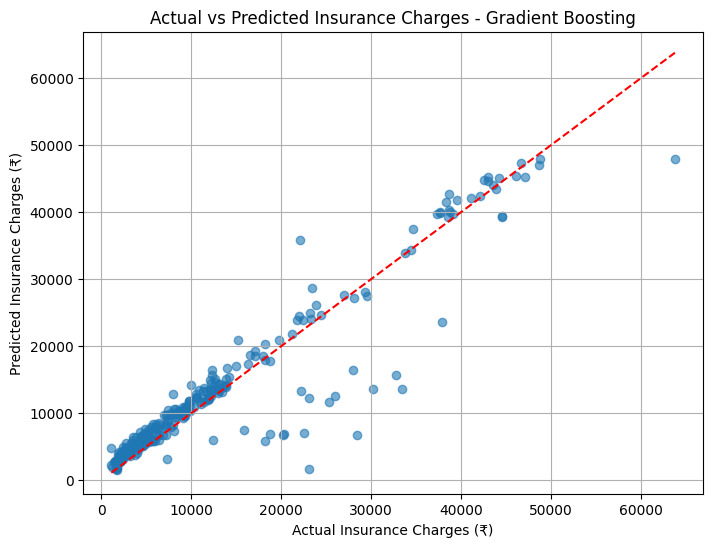

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, final_predictions, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Insurance Charges (₹)")
plt.ylabel("Predicted Insurance Charges (₹)")
plt.title("Actual vs Predicted Insurance Charges - Gradient Boosting")

plt.grid(True)
plt.show()


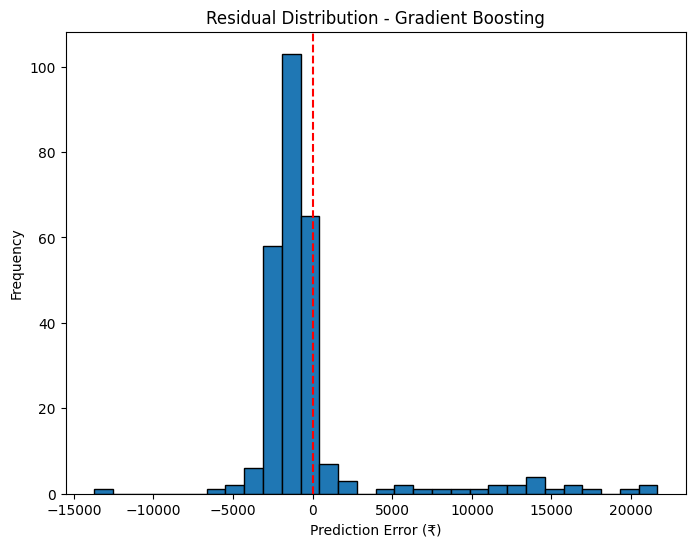

In [ ]:

residuals = y_test - final_predictions

plt.figure(figsize=(8, 6))

plt.hist(residuals, bins=30, edgecolor="black")

plt.xlabel("Prediction Error (₹)")
plt.ylabel("Frequency")
plt.title("Residual Distribution - Gradient Boosting")

plt.axvline(0, color="red", linestyle="--")

plt.show()


#Save the Final ML Model and Export Predictions

In [ ]:

import joblib

joblib.dump(final_model, "medibuddy_gradient_boosting_model.pkl")

print("Final model saved successfully!")


Final model saved successfully!


In [ ]:

prediction_results = pd.DataFrame({
    "Actual_Charges": y_test.values,
    "Predicted_Charges": final_predictions,
    "Prediction_Error": y_test.values - final_predictions
})

prediction_results.to_csv(
    "medibuddy_insurance_predictions.csv",
    index=False
)

display(prediction_results.head(10))

print("Prediction results exported successfully!")


,Actual_Charges,Predicted_Charges,Prediction_Error
0,9095.06825,10925.482111,-1830.413861
1,5272.17580,5706.412288,-434.236488
2,29330.98315,28037.933984,1293.049166
3,9301.89355,9626.887547,-324.993997
4,33750.29180,33868.649016,-118.357216
5,4536.25900,5156.732126,-620.473126
6,2117.33885,2835.419279,-718.080429
7,14210.53595,15451.832622,-1241.296672
8,3732.62510,5151.879832,-1419.254732
9,10264.44210,10917.210812,-652.768712


Prediction results exported successfully!


In [ ]:

from google.colab import files

files.download("medibuddy_gradient_boosting_model.pkl")
files.download("medibuddy_insurance_predictions.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Generate the Project Summary

In [ ]:

print("=" * 60)
print("MEDIBUDDY INSURANCE DATA ANALYSIS & ML CAPSTONE")
print("=" * 60)

print("\nPROJECT OBJECTIVE")
print("Analyze insurance charges and identify factors influencing")
print("insurance costs using statistical analysis and ML.")

print("\nDATASET SUMMARY")
print("Total Records:", len(df))
print("Total Features:", df.shape[1])
print("Average Insurance Charges:", round(df["charges in INR"].mean(), 2))
print("Median Insurance Charges:", round(df["charges in INR"].median(), 2))
print("Maximum Insurance Charges:", round(df["charges in INR"].max(), 2))
print("Minimum Insurance Charges:", round(df["charges in INR"].min(), 2))

print("\nFINAL MACHINE LEARNING MODEL")
print("Model: Gradient Boosting Regressor")
print("MAE:", round(mean_absolute_error(y_test, final_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, final_predictions)), 2))
print("R2 Score:", round(r2_score(y_test, final_predictions), 4))


MEDIBUDDY INSURANCE DATA ANALYSIS & ML CAPSTONE

PROJECT OBJECTIVE
Analyze insurance charges and identify factors influencing
insurance costs using statistical analysis and ML.

DATASET SUMMARY
Total Records: 1338
Total Features: 9
Average Insurance Charges: 13270.42
Median Insurance Charges: 9382.03
Maximum Insurance Charges: 63770.43
Minimum Insurance Charges: 1121.87

FINAL MACHINE LEARNING MODEL
Model: Gradient Boosting Regressor
MAE: 2404.9
RMSE: 4328.15
R2 Score: 0.8793
